<a href="https://colab.research.google.com/github/esero88/eser-portfolio/blob/main/pension-retention-analytics/notebooks/02_veri_temizleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EGM Veri Temizleme — BES Kalıcılık ve Rekabet Projesi

`01_egm_veri_toplama.ipynb` ile indirilen ham Excel dosyalarını analiz
edilebilir hale getirir. Her rapor kendi tidy CSV'sine yazılır.

## Raporların yapısı

İndirilen sekiz rapor dört farklı biçimde geliyor:

| Kalıp | Raporlar | Ne yapılıyor |
|---|---|---|
| Başlık satırı var, tarih veri içinde | `EGM-05-001` | İlk satır başlık olarak okunuyor |
| İki satırlı başlık | `EGM-05-006` | İki satır eşleştirilip tek başlığa indiriliyor |
| Başlık yok | `GR-01-010`, `GR-01-014`, `GR-01-018`, `GR-01-019` | Kolon adları elle veriliyor |
| Başlık var, ilk kolon adsız | `GR-01-015`, `GR-01-116` | İlk kolona ad veriliyor |

## Ortak kurallar

**Rapor tarihi dosya adından geliyor.** Dosyaların içinde (`EGM-05-001` hariç)
o bilgi yok. `GR-01-015_2026-09-29.xlsx` → `rapor_tarihi = 2026-09-29`.

**Her şey önce metin olarak okunuyor.** `dtype=str` olmadan `2003.10` gibi
kohort ayları `2003.1` float'ına dönüşüp ay bilgisi kayboluyor. Sayıya
çevirme, kolon kolon ve bilinçli yapılıyor.

**1925 tarihli dosyalar eleniyor.** EGM'nin tarih listesinde bozuk bir kayıt
var (`30 Temmuz 1925`); indirilmiş ama veri değil.

---

> **Kaynak:** Tüm istatistiksel veriler Emeklilik Gözetim Merkezi A.Ş.'ye (EGM)
> aittir. Kaynak gösterilmeden alıntı yapılamaz.

## 1. Hazırlık

Drive bağlanıyor, giriş ve çıkış klasörleri tanımlanıyor.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import re
import pandas as pd
from pathlib import Path

HAM   = Path("/content/drive/MyDrive/egm-bes-projesi/data/raw")
TEMIZ = Path("/content/drive/MyDrive/egm-bes-projesi/data/clean")
TEMIZ.mkdir(parents=True, exist_ok=True)

print("ham  :", HAM)
print("temiz:", TEMIZ)

Mounted at /content/drive
ham  : /content/drive/MyDrive/egm-bes-projesi/data/raw
temiz: /content/drive/MyDrive/egm-bes-projesi/data/clean


## 2. Yardımcı fonksiyonlar

`dosyalari_getir` bir raporun dosyalarını tarihiyle birlikte veriyor ve
1925 gibi geçersiz tarihleri eliyor.

`sayi` metni sayıya çeviriyor; boşlukları ve binlik ayracı olarak kullanılmış
olabilecek karakterleri temizliyor.

In [3]:
def dosyalari_getir(kod: str):
    """(tarih, yol) ikililerini tarihe göre sıralı döndürür."""
    klasor = HAM / kod
    if not klasor.exists():
        raise FileNotFoundError(f"{klasor} yok — önce toplama defterini çalıştırın")

    cikti = []
    for yol in klasor.glob("*.xlsx"):
        m = re.search(r"(\d{4})-(\d{2})-(\d{2})", yol.stem)
        if not m:
            print(f"  ATLANDI (tarih okunamadı): {yol.name}")
            continue
        tarih = pd.Timestamp(f"{m.group(1)}-{m.group(2)}-{m.group(3)}")
        if tarih.year < 2000:                      # EGM'nin 1925 kaydı
            print(f"  ATLANDI (geçersiz tarih): {yol.name}")
            continue
        cikti.append((tarih, yol))

    cikti.sort()
    return cikti


def sayi(seri: pd.Series) -> pd.Series:
    """Metin seriyi sayıya çevirir; çevrilemeyen NaN olur."""
    return pd.to_numeric(
        seri.astype(str)
            .str.replace("\u00a0", "", regex=False)   # kırılmaz boşluk
            .str.replace(" ", "", regex=False)
            .str.strip()
            .replace({"": None, "nan": None, "None": None, "-": None}),
        errors="coerce",
    )


def oku_ham(yol: Path) -> pd.DataFrame:
    """Dosyayı başlıksız ve tamamen metin olarak okur."""
    return pd.read_excel(yol, dtype=str, header=None)


def ozet(df: pd.DataFrame, ad: str) -> None:
    print(f"{ad:<14} {df.shape[0]:>7,} satır × {df.shape[1]} kolon"
          f"   |  {df['rapor_tarihi'].min():%Y-%m-%d} → {df['rapor_tarihi'].max():%Y-%m-%d}")

## 3. GR-01-015 — kohort kalıcılık paneli

Projenin ana tablosu. Her dosya, o rapor tarihi itibarıyla **her giriş ayının**
sonlanma oranını veriyor. 83 dosya × ~270 kohort ≈ 22 bin satırlık bir panel.

Kolonlar: ilk kolon adsız (giriş ayı, `2003.10` biçiminde), sonra sonlanma
oranı ve yürürlüğe giren sözleşme adedi.

`kohort_ay` metin olarak okunup `2003-10` biçimine çevriliyor. Float'a
dönüşürse `2003.10` ile `2003.01` ayrımı bozulur.

**Kıdem** burada türetiliyor: rapor tarihi ile kohort ayı arasındaki ay farkı.
Eşit kıdemde karşılaştırmayı mümkün kılan kolon bu.

In [4]:
def temizle_gr_01_015():
    parcalar = []
    for tarih, yol in dosyalari_getir("GR-01-015"):
        ham = oku_ham(yol)
        ham = ham.iloc[1:]                      # başlık satırı
        ham.columns = ["kohort_ay", "sonlanma_orani", "sozlesme_adedi"]
        ham = ham.assign(rapor_tarihi=tarih)
        parcalar.append(ham)

    df = pd.concat(parcalar, ignore_index=True)
    df["kohort_ay"]      = df["kohort_ay"].str.strip().str.replace(".", "-", regex=False)
    df["sonlanma_orani"] = sayi(df["sonlanma_orani"])
    df["sozlesme_adedi"] = sayi(df["sozlesme_adedi"]).astype("Int64")
    df = df.dropna(subset=["kohort_ay"])

    # kıdem: rapor tarihi - kohort ayı, ay cinsinden
    kohort_ts = pd.to_datetime(df["kohort_ay"], format="%Y-%m", errors="coerce")
    df["kidem_ay"] = ((df["rapor_tarihi"].dt.year  - kohort_ts.dt.year) * 12 +
                      (df["rapor_tarihi"].dt.month - kohort_ts.dt.month))

    df = df[["rapor_tarihi", "kohort_ay", "kidem_ay", "sonlanma_orani", "sozlesme_adedi"]]
    return df.sort_values(["rapor_tarihi", "kohort_ay"]).reset_index(drop=True)


gr015 = temizle_gr_01_015()
ozet(gr015, "GR-01-015")
gr015.head()

GR-01-015       19,494 satır × 5 kolon   |  2018-12-30 → 2026-09-29


,rapor_tarihi,kohort_ay,kidem_ay,sonlanma_orani,sozlesme_adedi
0,2018-12-30,2003-10,182,53.61,388
1,2018-12-30,2003-11,181,58.26,4715
2,2018-12-30,2003-12,180,58.01,16983
3,2018-12-30,2004-01,179,57.69,16284
4,2018-12-30,2004-02,178,58.92,15917


### Doğrulama — sözleşme adedi sabit mi?

Geçmişte kurulan sözleşme sayısı sonradan değişmez. Aynı kohort için bütün
rapor tarihlerinde aynı `sozlesme_adedi` görünmeli.

Değişiyorsa iki ihtimal var: EGM veriyi revize etmiş, ya da birleştirmede hata
var. Hangisi olduğunu farkın büyüklüğünden anlarsın — birkaç sözleşmelik
oynama revizyon, kat kat fark hatadır.

In [5]:
kontrol = (gr015.groupby("kohort_ay")["sozlesme_adedi"]
                 .agg(["nunique", "min", "max"])
                 .query("nunique > 1"))

if kontrol.empty:
    print("Sözleşme adedi tüm kohortlarda sabit.")
else:
    kontrol["fark"] = kontrol["max"] - kontrol["min"]
    kontrol["fark_yuzde"] = (kontrol["fark"] / kontrol["min"] * 100).round(2)
    print(f"{len(kontrol)} kohortta sözleşme adedi değişiyor:")
    display(kontrol.sort_values("fark_yuzde", ascending=False).head(15))

253 kohortta sözleşme adedi değişiyor:


,nunique,min,max,fark,fark_yuzde
kohort_ay,,,,,
2023-08,17,201090,209000,7910,3.93
2022-08,22,139911,144537,4626,3.31
2022-02,17,166886,172042,5156,3.09
2020-07,10,91954,94769,2815,3.06
2022-06,17,152432,156882,4450,2.92
2022-07,18,137895,141284,3389,2.46
2021-12,10,174256,178099,3843,2.21
2022-03,18,193969,198170,4201,2.17
2022-10,20,185222,189067,3845,2.08


## 4. EGM-05-006 — şirket bazında fon büyüklükleri

Başlığı iki satır:

```
Emeklilik Şirketi | Gönüllü BES | Gönüllü BES | Otomatik Katılım | ...
            (boş) |      Faizli |     Faizsiz |          Faizsiz | ...
```

Sıraya güvenilmiyor — Otomatik Katılım'da **Faizsiz önce, Faizli sonra**
geliyor, diğer segmentlerde tersi. İki satır hücre hücre eşleştirilip kolon
adı üretiliyor.

Çıktı uzun formatta: `rapor_tarihi, emeklilik_sirketi, segment, faiz_tipi, tutar`.
Hem SQL hem Tableau bu biçimi tercih ediyor.

`Genel Toplam` satırı şirket değil; ayrılıp doğrulamada kullanılıyor.

In [6]:
def baslik_birlestir(ust: pd.Series, alt: pd.Series) -> list[str]:
    """İki başlık satırını hücre hücre eşleştirip tek başlık üretir."""
    adlar, son_ust = [], ""
    for u, a in zip(ust, alt):
        u = "" if pd.isna(u) else str(u).strip()
        a = "" if pd.isna(a) else str(a).strip()
        if u:
            son_ust = u
        adlar.append(f"{son_ust} {a}".strip() if a else son_ust)
    return adlar


def slug(s: str) -> str:
    esle = str.maketrans("çğıöşüÇĞİÖŞÜ", "cgiosuCGIOSU")
    return re.sub(r"[^a-z0-9]+", "_", s.translate(esle).lower()).strip("_")


def temizle_egm_05_006():
    parcalar = []
    for tarih, yol in dosyalari_getir("EGM-05-006"):
        ham = oku_ham(yol)
        adlar = baslik_birlestir(ham.iloc[0], ham.iloc[1])
        veri = ham.iloc[2:].copy()
        veri.columns = adlar
        veri = veri.assign(rapor_tarihi=tarih)
        parcalar.append(veri)

    df = pd.concat(parcalar, ignore_index=True)
    sirket_kolonu = df.columns[0]
    df = df.rename(columns={sirket_kolonu: "emeklilik_sirketi"})
    df["emeklilik_sirketi"] = df["emeklilik_sirketi"].str.strip()
    df = df.dropna(subset=["emeklilik_sirketi"])

    # Genel Toplam satırını ayır
    toplam_maske = df["emeklilik_sirketi"].str.contains("Genel Toplam", case=False, na=False)
    toplamlar = df[toplam_maske].copy()
    df = df[~toplam_maske].copy()

    deger_kolonlari = [k for k in df.columns
                       if k not in ("emeklilik_sirketi", "rapor_tarihi")]

    uzun = df.melt(id_vars=["rapor_tarihi", "emeklilik_sirketi"],
                   value_vars=deger_kolonlari,
                   var_name="kolon", value_name="tutar")
    uzun["tutar"] = sayi(uzun["tutar"])
    uzun = uzun.dropna(subset=["tutar"])

    # "Gönüllü BES Faizli" -> segment + faiz tipi
    uzun["faiz_tipi"] = uzun["kolon"].str.extract(r"(Faizli|Faizsiz)$", expand=False)
    uzun["segment"]   = (uzun["kolon"]
                         .str.replace(r"\s*(Faizli|Faizsiz)$", "", regex=True)
                         .map(slug))
    uzun["faiz_tipi"] = uzun["faiz_tipi"].fillna("toplam").map(slug)

    uzun = uzun[["rapor_tarihi", "emeklilik_sirketi", "segment", "faiz_tipi", "tutar"]]
    return uzun.sort_values(["rapor_tarihi", "emeklilik_sirketi"]).reset_index(drop=True), toplamlar


egm006, egm006_toplam = temizle_egm_05_006()
ozet(egm006, "EGM-05-006")
print("\nsegmentler :", sorted(egm006["segment"].unique()))
print("faiz tipleri:", sorted(egm006["faiz_tipi"].unique()))
print("şirket      :", egm006["emeklilik_sirketi"].nunique())
egm006.head()

  ATLANDI (geçersiz tarih): EGM-05-006_1925-07-30.xlsx
EGM-05-006       6,046 satır × 5 kolon   |  2019-12-30 → 2026-09-29

segmentler : ['devlet_katkisi', 'gonullu_bes', 'otomatik_katilim', 'toplam']
faiz tipleri: ['faizli', 'faizsiz', 'toplam']
şirket      : 20


,rapor_tarihi,emeklilik_sirketi,segment,faiz_tipi,tutar
0,2019-12-30,Aegon Emeklilik ve Hayat A.Ş.,gonullu_bes,faizli,1.387627e+08
1,2019-12-30,Aegon Emeklilik ve Hayat A.Ş.,devlet_katkisi,faizli,1.743635e+07
2,2019-12-30,Aegon Emeklilik ve Hayat A.Ş.,toplam,toplam,1.561990e+08
3,2019-12-30,AgeSA Hayat ve Emeklilik A.Ş.,gonullu_bes,faizli,1.930308e+10
4,2019-12-30,AgeSA Hayat ve Emeklilik A.Ş.,gonullu_bes,faizsiz,5.988800e+05


### Doğrulama — şirketler toplamı, Genel Toplam'a eşit mi?

EGM her dosyada bir `Genel Toplam` satırı veriyor. Şirket satırlarının toplamı
ona eşit olmalı. Tutmuyorsa başlık eşleştirmesi ya da sayıya çevirme hatalı
demektir.

Kuruş düzeyinde minik farklar yuvarlamadan olabilir; burada binde birden
büyük sapmalar işaretleniyor.

In [7]:
# "Toplam" kolonunu bulup her iki tarafı karşılaştır
hesap = (egm006[egm006["segment"] == "toplam"]
         .groupby("rapor_tarihi")["tutar"].sum()
         .rename("hesaplanan"))

beyan = egm006_toplam.set_index("rapor_tarihi")
toplam_kolonu = [k for k in beyan.columns if slug(str(k)) == "toplam"]

if not toplam_kolonu or hesap.empty:
    print("Toplam kolonu bulunamadı — doğrulama atlandı.")
    print("Mevcut segmentler:", sorted(egm006['segment'].unique()))
else:
    beyan = sayi(beyan[toplam_kolonu[0]]).rename("beyan")
    kars = pd.concat([hesap, beyan], axis=1).dropna()
    kars["sapma_yuzde"] = ((kars["hesaplanan"] - kars["beyan"]).abs()
                           / kars["beyan"] * 100)
    kotu = kars[kars["sapma_yuzde"] > 0.1]
    if kotu.empty:
        print(f"{len(kars)} rapor tarihinin hepsinde şirket toplamları Genel Toplam ile uyumlu.")
    else:
        print(f"{len(kotu)} tarihte sapma var:")
        display(kotu.sort_values("sapma_yuzde", ascending=False).head(10))

71 rapor tarihinin hepsinde şirket toplamları Genel Toplam ile uyumlu.


## 5. İki kolonlu, başlıksız raporlar

`GR-01-010`, `GR-01-014`, `GR-01-018`, `GR-01-019` aynı kalıpta: başlık satırı
yok, ilk satır boş, iki kolon var. Tek fark kolonların ne anlama geldiği.

Tek bir fonksiyonla okunup her birine kendi kolon adları veriliyor.

In [8]:
def temizle_iki_kolon(kod: str, etiket_adi: str, deger_adi: str) -> pd.DataFrame:
    parcalar = []
    for tarih, yol in dosyalari_getir(kod):
        ham = oku_ham(yol)
        # ilk satır tamamen boşsa başlık yeridir, atla
        if ham.iloc[0].isna().all():
            ham = ham.iloc[1:]
        ham = ham.iloc[:, :2].copy()
        ham.columns = [etiket_adi, deger_adi]
        ham = ham.assign(rapor_tarihi=tarih)
        parcalar.append(ham)

    df = pd.concat(parcalar, ignore_index=True)
    df[etiket_adi] = df[etiket_adi].str.strip()
    df[deger_adi]  = sayi(df[deger_adi])
    df = df.dropna(subset=[etiket_adi, deger_adi])
    df = df[["rapor_tarihi", etiket_adi, deger_adi]]
    return df.sort_values(["rapor_tarihi", etiket_adi]).reset_index(drop=True)


gr010 = temizle_iki_kolon("GR-01-010", "sonlanma_nedeni",      "adet")
gr014 = temizle_iki_kolon("GR-01-014", "kidem_araligi",        "yuzde")
gr018 = temizle_iki_kolon("GR-01-018", "onceki_sirkette_sure", "adet")
gr019 = temizle_iki_kolon("GR-01-019", "gosterge",             "adet")

for ad, df in [("GR-01-010", gr010), ("GR-01-014", gr014),
               ("GR-01-018", gr018), ("GR-01-019", gr019)]:
    ozet(df, ad)

print("\nsonlanma nedenleri:", sorted(gr010["sonlanma_nedeni"].unique()))
gr010.head()

GR-01-010          194 satır × 3 kolon   |  2018-12-30 → 2026-09-29
GR-01-014          156 satır × 3 kolon   |  2018-12-30 → 2025-12-30
GR-01-018           80 satır × 3 kolon   |  2018-12-30 → 2025-12-30
GR-01-019           58 satır × 3 kolon   |  2018-12-30 → 2026-09-29

sonlanma nedenleri: ['Başka Şirkete Aktarım', 'Cayma', 'Emeklilik', 'Hesap Birleştirme', 'Red / Fesih', 'Sistemden Çıkış', 'Vefat / Maluliyet']


,rapor_tarihi,sonlanma_nedeni,adet
0,2018-12-30,Başka Şirkete Aktarım,520201
1,2018-12-30,Emeklilik,86718
2,2018-12-30,Hesap Birleştirme,207753
3,2018-12-30,Red / Fesih,147223
4,2018-12-30,Sistemden Çıkış,6792940


### GR-01-019 — cayma oranı

Bu rapor iki satır veriyor: cayma hakkını kullanan sayısı ve o dönem yürürlüğe
giren sözleşme sayısı. Oranı biz hesaplıyoruz.

Etiketler uzun olduğu için "Cayma Hakkı Kullanan" geçen satır pay, diğeri
payda kabul ediliyor.

In [9]:
pay   = gr019[gr019["gosterge"].str.contains("Kullanan", case=False, na=False)]
payda = gr019[~gr019["gosterge"].str.contains("Kullanan", case=False, na=False)]

cayma = (pay.groupby("rapor_tarihi")["adet"].sum().rename("cayma_kullanan")
         .to_frame()
         .join(payda.groupby("rapor_tarihi")["adet"].sum().rename("yururluge_giren")))

cayma["cayma_orani"] = (cayma["cayma_kullanan"] / cayma["yururluge_giren"] * 100).round(2)
cayma = cayma.reset_index()

print(f"{len(cayma)} rapor tarihi")
print(f"cayma oranı aralığı: %{cayma['cayma_orani'].min():.2f} – %{cayma['cayma_orani'].max():.2f}")
cayma.tail()

29 rapor tarihi
cayma oranı aralığı: %5.11 – %11.39


,rapor_tarihi,cayma_kullanan,yururluge_giren,cayma_orani
24,2025-09-29,142767,1470476,9.71
25,2025-12-30,197803,2038187,9.70
26,2026-03-30,41090,527133,7.79
27,2026-06-29,99053,971839,10.19
28,2026-09-29,162328,1425318,11.39


## 6. Başlıklı raporlar

`GR-01-116` (giriş yılına göre çıkış ve tahsilat oranları) ve `EGM-05-001`
(fon bazında kesinti oranları) normal başlık satırıyla geliyor.

`EGM-05-001` tarihi kendi içinde de taşıyor — dosya adından gelen tarihle
tutarlı mı, kontrol ediliyor.

In [10]:
def temizle_gr_01_116() -> pd.DataFrame:
    parcalar = []
    for tarih, yol in dosyalari_getir("GR-01-116"):
        ham = oku_ham(yol).iloc[1:].copy()
        ham.columns = ["yururluk_yili", "cikis_orani", "tahsilat_orani"]
        parcalar.append(ham.assign(rapor_tarihi=tarih))

    df = pd.concat(parcalar, ignore_index=True)
    df["yururluk_yili"]  = sayi(df["yururluk_yili"]).astype("Int64")
    df["cikis_orani"]    = sayi(df["cikis_orani"])
    df["tahsilat_orani"] = sayi(df["tahsilat_orani"])
    df = df.dropna(subset=["yururluk_yili"])
    return (df[["rapor_tarihi", "yururluk_yili", "cikis_orani", "tahsilat_orani"]]
            .sort_values(["rapor_tarihi", "yururluk_yili"]).reset_index(drop=True))


def temizle_egm_05_001() -> pd.DataFrame:
    parcalar = []
    for tarih, yol in dosyalari_getir("EGM-05-001"):
        ham = oku_ham(yol).iloc[1:].copy()
        ham.columns = ["tarih_icerik", "spk_fon_kodu", "fon_unvani", "kesinti_orani"]
        parcalar.append(ham.assign(rapor_tarihi=tarih))

    df = pd.concat(parcalar, ignore_index=True)
    df["kesinti_orani"] = sayi(df["kesinti_orani"])
    for k in ("spk_fon_kodu", "fon_unvani"):
        df[k] = df[k].str.strip()
    df = df.dropna(subset=["spk_fon_kodu"])

    # dosya adındaki tarih ile içerikteki tarih tutuyor mu?
    icerik = pd.to_datetime(df["tarih_icerik"], format="%d.%m.%Y", errors="coerce")
    uyumsuz = (icerik.notna() & (icerik != df["rapor_tarihi"])).sum()
    print(f"  dosya adı / içerik tarihi uyumsuzluğu: {uyumsuz} satır")

    return (df[["rapor_tarihi", "spk_fon_kodu", "fon_unvani", "kesinti_orani"]]
            .sort_values(["rapor_tarihi", "spk_fon_kodu"]).reset_index(drop=True))


gr116   = temizle_gr_01_116()
egm001  = temizle_egm_05_001()

ozet(gr116,  "GR-01-116")
ozet(egm001, "EGM-05-001")
egm001.head()

  ATLANDI (geçersiz tarih): EGM-05-001_1925-07-30.xlsx
  dosya adı / içerik tarihi uyumsuzluğu: 29952 satır
GR-01-116        1,088 satır × 4 kolon   |  2022-09-29 → 2026-09-29
EGM-05-001      29,952 satır × 4 kolon   |  2020-03-30 → 2026-09-29


,rapor_tarihi,spk_fon_kodu,fon_unvani,kesinti_orani
0,2020-03-30,AAJ,Avivasa Emeklilik Ve Hayat A.Ş. OKS Standart E...,2.33
1,2020-03-30,ABE,Anadolu Hayat Emeklilik A.Ş. B.R.I.C Ülkeler Y...,6.05
2,2020-03-30,ACV,Allianz Yaşam ve Emeklilik A.Ş. Başlangıç Katı...,2.33
3,2020-03-30,AE1,Avivasa Emeklilik ve Hayat A.Ş. Birinci Para P...,2.88
4,2020-03-30,AE2,Avivasa Emeklilik ve Hayat A.Ş. Borçlanma Araç...,5.21


## 7. Yazma

Her tablo kendi CSV'sine yazılıyor. `utf-8-sig` kodlaması Excel'in Türkçe
karakterleri doğru göstermesi için.

Dosyalar `data/clean/` altına düşüyor; ham veriden farklı olarak bunlar küçük
ve metin tabanlı, repoya konabilir.

In [11]:
tablolar = {
    "gr_01_015_kohort_panel":  gr015,
    "gr_01_010_sonlanma_nedeni": gr010,
    "gr_01_014_kidem_dagilimi":  gr014,
    "gr_01_018_sirket_aktarim":  gr018,
    "gr_01_019_cayma":           cayma,
    "gr_01_116_giris_yili":      gr116,
    "egm_05_006_fon_buyukluk":   egm006,
    "egm_05_001_kesinti_orani":  egm001,
}

for ad, df in tablolar.items():
    yol = TEMIZ / f"{ad}.csv"
    df.to_csv(yol, index=False, encoding="utf-8-sig")
    print(f"{ad:<28} {len(df):>8,} satır  ->  {yol.name}  ({yol.stat().st_size/1024:,.0f} KB)")

print(f"\nKlasör: {TEMIZ}")

gr_01_015_kohort_panel         19,494 satır  ->  gr_01_015_kohort_panel.csv  (663 KB)
gr_01_010_sonlanma_nedeni         194 satır  ->  gr_01_010_sonlanma_nedeni.csv  (7 KB)
gr_01_014_kidem_dagilimi          156 satır  ->  gr_01_014_kidem_dagilimi.csv  (4 KB)
gr_01_018_sirket_aktarim           80 satır  ->  gr_01_018_sirket_aktarim.csv  (2 KB)
gr_01_019_cayma                    29 satır  ->  gr_01_019_cayma.csv  (1 KB)
gr_01_116_giris_yili            1,088 satır  ->  gr_01_116_giris_yili.csv  (30 KB)
egm_05_006_fon_buyukluk         6,046 satır  ->  egm_05_006_fon_buyukluk.csv  (459 KB)
egm_05_001_kesinti_orani       29,952 satır  ->  egm_05_001_kesinti_orani.csv  (3,017 KB)

Klasör: /content/drive/MyDrive/egm-bes-projesi/data/clean


## 8. İlk bakış — kıdem eğrisi

Veri temizlendi; asıl soruya ilk bakış.

Her kohortun belirli kıdemlerdeki sonlanma oranını yan yana koyuyoruz. Ham
oranları karşılaştırmak yanıltıcı olurdu: 2003 kohortu 23 yıl, 2025 kohortu
1 yıl maruz kalmış. `kidem_ay` bunu çözüyor — aynı kıdemdeki kohortları
karşılaştırıyoruz.

Bakılacak şey: yeni kohortlar eski kohortlardan daha iyi mi tutunuyor, ve
devlet katkısı hak ediş eşiklerinde (36, 72, 120 ay) eğride kırılma var mı.

In [12]:
# hangi kıdemlerde kaç gözlem var?
sayim = gr015["kidem_ay"].value_counts().sort_index()
print(f"kıdem aralığı: {gr015['kidem_ay'].min()} – {gr015['kidem_ay'].max()} ay")

hedef_kidemler = [12, 24, 36, 60, 120]
mevcut = [k for k in hedef_kidemler if sayim.get(k, 0) > 0]
print("hedef kıdemlerdeki kohort sayısı:",
      {k: int(sayim.get(k, 0)) for k in hedef_kidemler})

if not mevcut:
    print("\nHiçbir hedef kıdemde gözlem yok — rapor tarihi serisi çok kısa.")
else:
    kesit = (gr015[gr015["kidem_ay"].isin(mevcut)]
             .pivot_table(index="kohort_ay", columns="kidem_ay",
                          values="sonlanma_orani", aggfunc="first"))
    kesit.columns = [f"{k}. ay" for k in kesit.columns]
    kesit["giris_yili"] = kesit.index.str[:4].astype(int)

    yillik = kesit.groupby("giris_yili").mean().round(1)
    print("\nGiriş yılına göre ortalama sonlanma oranı (%), eşit kıdemde:")
    display(yillik)

kıdem aralığı: 0 – 275 ay
hedef kıdemlerdeki kohort sayısı: {12: 83, 24: 83, 36: 83, 60: 83, 120: 83}

Giriş yılına göre ortalama sonlanma oranı (%), eşit kıdemde:


,12. ay,24. ay,36. ay,60. ay,120. ay
giris_yili,,,,,
2008,NaN,NaN,NaN,NaN,52.0
2009,NaN,NaN,NaN,NaN,56.1
2010,NaN,NaN,NaN,NaN,57.5
2011,NaN,NaN,NaN,NaN,56.5
2012,NaN,NaN,NaN,NaN,58.4
2013,NaN,NaN,NaN,42.6,59.3
2014,NaN,NaN,NaN,45.5,60.5
2015,NaN,NaN,30.2,45.9,61.6
2016,NaN,21.0,30.1,45.7,60.0


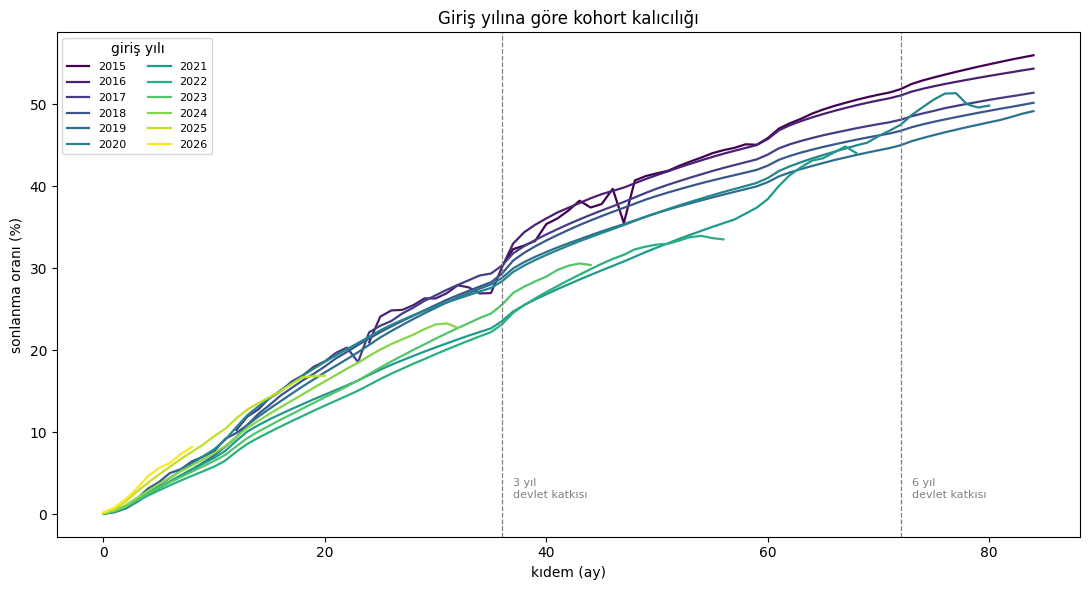

In [13]:
import matplotlib.pyplot as plt

egri = (gr015[gr015["kidem_ay"].between(0, 84)]
        .assign(giris_yili=lambda d: d["kohort_ay"].str[:4].astype(int))
        .query("giris_yili >= 2015")
        .groupby(["giris_yili", "kidem_ay"])["sonlanma_orani"].mean()
        .unstack(0))

fig, ax = plt.subplots(figsize=(11, 6))
egri.plot(ax=ax, linewidth=1.6, colormap="viridis")
for esik in (36, 72):
    ax.axvline(esik, color="grey", linestyle="--", linewidth=0.9)
    ax.text(esik + 1, 2, f"{esik//12} yıl\ndevlet katkısı", fontsize=8, color="grey")
ax.set_xlabel("kıdem (ay)"); ax.set_ylabel("sonlanma oranı (%)")
ax.set_title("Giriş yılına göre kohort kalıcılığı")
ax.legend(title="giriş yılı", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

36. ay  |  önceki 6 ay: 0.652 puan/ay   sonraki 6 ay: 0.932   fark: +0.280
72. ay  |  önceki 6 ay: 0.399 puan/ay   sonraki 6 ay: 0.425   fark: +0.026


<Axes: title={'center': 'Kıdem ayına göre aylık sonlanma hızı (puan/ay)'}, xlabel='kidem_ay'>

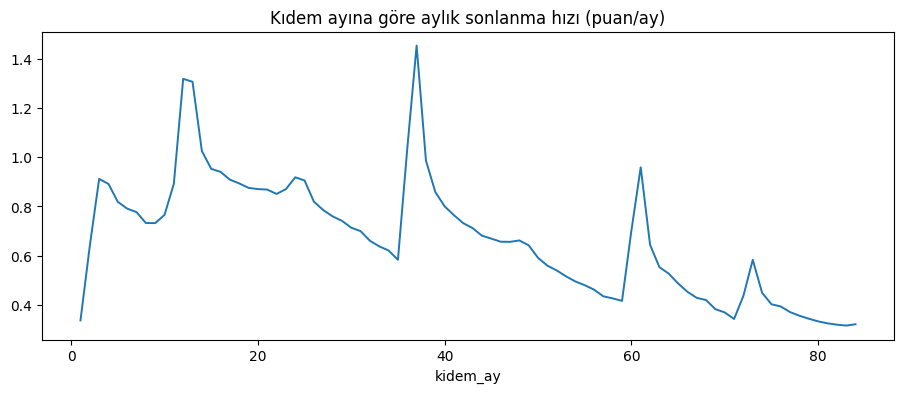

In [14]:
artis = (gr015.sort_values(["kohort_ay", "kidem_ay"])
         .assign(aylik=lambda d: d.groupby("kohort_ay")["sonlanma_orani"].diff()))

profil = (artis[artis["kidem_ay"].between(1, 84)]
          .groupby("kidem_ay")["aylik"].mean())

for esik in (36, 72):
    once  = profil.loc[esik-6:esik-1].mean()
    sonra = profil.loc[esik+1:esik+6].mean()
    print(f"{esik}. ay  |  önceki 6 ay: {once:.3f} puan/ay   "
          f"sonraki 6 ay: {sonra:.3f}   fark: {sonra-once:+.3f}")

profil.plot(figsize=(11,4), linewidth=1.4,
            title="Kıdem ayına göre aylık sonlanma hızı (puan/ay)")

In [15]:
def taban(k, pencere=5, bosluk=2):
    sol = profil.loc[k-bosluk-pencere : k-bosluk]
    sag = profil.loc[k+bosluk : k+bosluk+pencere]
    return pd.concat([sol, sag]).mean()

notlar = {13: "1 yıl", 25: "2 yıl", 37: "3 yıl — devlet katkısı %15",
          49: "4 yıl", 61: "5 yıl", 73: "6 yıl — devlet katkısı %35"}

print(f"{'ay':>4} {'tepe':>7} {'taban':>7} {'fazla':>8}   not")
for k, nt in notlar.items():
    if k not in profil.index:
        continue
    tepe = profil.loc[k-1:k+1].max()
    b = taban(k)
    print(f"{k:>4} {tepe:>7.3f} {b:>7.3f} {tepe-b:>+8.3f}   {nt}")

  ay    tepe   taban    fazla   not
  13   1.319   0.844   +0.474   1 yıl
  25   0.918   0.799   +0.119   2 yıl
  37   1.454   0.705   +0.749   3 yıl — devlet katkısı %15
  49   0.661   0.596   +0.065   4 yıl
  61   0.959   0.465   +0.494   5 yıl
  73   0.583   0.382   +0.200   6 yıl — devlet katkısı %35


---

## Sonraki adım

1. **Ambar** — temiz CSV'lerin PostgreSQL'e yüklenmesi, yıldız şema.
2. **Metrik sözlüğü** — kalıcılık, cayma oranı, aktif katılımcı tanımları.
3. **Dashboard** — Tableau: kohort kalıcılık eğrisi, sonlanma nedenleri,
   pazar payı, maliyet karşılaştırması.
4. **Agent** — doğal dilden SQL, 30 soruluk doğruluk testi.